# Phase 2: The result
**Question:** is there a real difference between `gate_30` and `gate_40`, and how big is it?

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

In [2]:
df = pd.read_csv('cookie_cats.csv')
df_clean = pd.read_csv('cookie_cats_clean_for_rounds.csv')

In [3]:
np.random.seed(42)

In [5]:
def cohens_h(p1, p2):
    return 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))
 
def bootstrap_ci_diff_proportions(a, b, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    a = np.asarray(a); b = np.asarray(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = sa.mean() - sb.mean()
    return np.percentile(diffs, [2.5, 97.5]), diffs.mean()
 
def bootstrap_ci_diff_means(a, b, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    a = np.asarray(a); b = np.asarray(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = sa.mean() - sb.mean()
    return np.percentile(diffs, [2.5, 97.5]), diffs.mean()
 
results = {}

def run_proportion_test(metric):
    g30 = df[df['version']=='gate_30'][metric].astype(int)
    g40 = df[df['version']=='gate_40'][metric].astype(int)
 
    p30, p40 = g30.mean(), g40.mean()
    n30, n40 = len(g30), len(g40)
 
    count = np.array([g30.sum(), g40.sum()])
    nobs = np.array([n30, n40])
    p_pool = count.sum()/nobs.sum()
    se = np.sqrt(p_pool*(1-p_pool)*(1/n30 + 1/n40))
    z = (p30 - p40) / se
    p_val = 2*(1 - stats.norm.cdf(abs(z)))
 
    table = pd.crosstab(df['version'], df[metric])
    chi2, p_chi2, dof, exp = stats.chi2_contingency(table, correction=False)
 
    h = cohens_h(p30, p40)
    ci, boot_mean = bootstrap_ci_diff_proportions(g30, g40)
 
    print(f"\n--- {metric} ---")
    print(f"gate_30 (control):   {p30:.4%}  (n={n30})")
    print(f"gate_40 (treatment): {p40:.4%}  (n={n40})")
    print(f"Absolute difference (control - treatment): {(p30-p40)*100:.3f} pp")
    print(f"Two-proportion z-test: z={z:.4f}, p={p_val:.6f}")
    print(f"Chi-square cross-check: chi2={chi2:.4f}, p={p_chi2:.6f}")
    print(f"Cohen's h (effect size): {h:.4f}  -> {'negligible' if abs(h)<0.2 else 'small' if abs(h)<0.5 else 'medium+'}")
    print(f"Bootstrap 95% CI on difference (control-treatment): [{ci[0]*100:.3f}pp, {ci[1]*100:.3f}pp]")
 
    return dict(p30=p30, p40=p40, n30=n30, n40=n40, z=z, p_val=p_val,
                chi2=chi2, p_chi2=p_chi2, h=h, ci=ci)
 
results['retention_1'] = run_proportion_test('retention_1')
results['retention_7'] = run_proportion_test('retention_7')
 
print(f"\n--- sum_gamerounds (outlier excluded) ---")
r30 = df_clean[df_clean['version']=='gate_30']['sum_gamerounds']
r40 = df_clean[df_clean['version']=='gate_40']['sum_gamerounds']
 
print(f"gate_30: mean={r30.mean():.2f}, median={r30.median():.1f}, n={len(r30)}")
print(f"gate_40: mean={r40.mean():.2f}, median={r40.median():.1f}, n={len(r40)}")
 
sub30 = r30.sample(min(5000,len(r30)), random_state=1)
shapiro_stat, shapiro_p = stats.shapiro(sub30)
print(f"Shapiro-Wilk normality check (subsample n=5000): W={shapiro_stat:.4f}, p={shapiro_p:.2e}")
print("-> Not normal (heavily right-skewed) -> Mann-Whitney U is the appropriate test, not a t-test")
 
u_stat, mw_p = stats.mannwhitneyu(r30, r40, alternative='two-sided')
n1, n2 = len(r30), len(r40)
rank_biserial = 1 - (2*u_stat)/(n1*n2)
print(f"Mann-Whitney U: U={u_stat:.1f}, p={mw_p:.4f}")
print(f"Rank-biserial correlation (effect size): {rank_biserial:.4f}")
 
ci_means, boot_mean_diff = bootstrap_ci_diff_means(r30, r40)
print(f"Bootstrap 95% CI on mean difference (control-treatment): [{ci_means[0]:.3f}, {ci_means[1]:.3f}]")
 
results['sum_gamerounds'] = dict(mean30=r30.mean(), mean40=r40.mean(), median30=r30.median(),
                                   median40=r40.median(), u_stat=u_stat, mw_p=mw_p,
                                   rank_biserial=rank_biserial, ci_means=ci_means)


--- retention_1 ---
gate_30 (control):   44.8188%  (n=44700)
gate_40 (treatment): 44.2283%  (n=45489)
Absolute difference (control - treatment): 0.591 pp
Two-proportion z-test: z=1.7841, p=0.074410
Chi-square cross-check: chi2=3.1830, p=0.074410
Cohen's h (effect size): 0.0119  -> negligible
Bootstrap 95% CI on difference (control-treatment): [-0.053pp, 1.228pp]



--- retention_7 ---
gate_30 (control):   19.0201%  (n=44700)
gate_40 (treatment): 18.2000%  (n=45489)
Absolute difference (control - treatment): 0.820 pp
Two-proportion z-test: z=3.1644, p=0.001554
Chi-square cross-check: chi2=10.0132, p=0.001554
Cohen's h (effect size): 0.0211  -> negligible
Bootstrap 95% CI on difference (control-treatment): [0.325pp, 1.344pp]

--- sum_gamerounds (outlier excluded) ---
gate_30: mean=51.34, median=17.0, n=44699
gate_40: mean=51.30, median=16.0, n=45489
Shapiro-Wilk normality check (subsample n=5000): W=0.4806, p=5.66e-81
-> Not normal (heavily right-skewed) -> Mann-Whitney U is the appropriate test, not a t-test
Mann-Whitney U: U=1024285761.5, p=0.0509
Rank-biserial correlation (effect size): -0.0075


Bootstrap 95% CI on mean difference (control-treatment): [-1.288, 1.343]


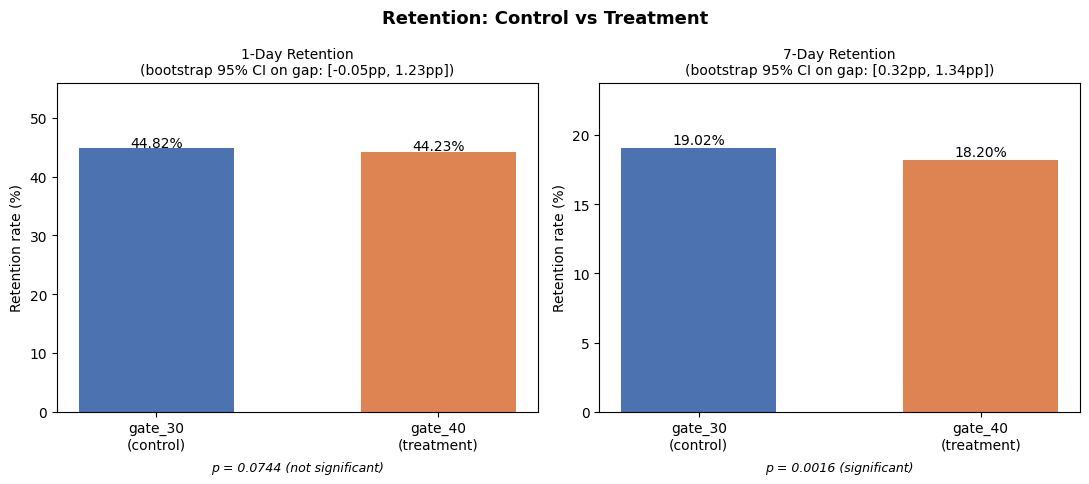

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, metric, title in zip(axes, ['retention_1', 'retention_7'], ['1-Day Retention', '7-Day Retention']):
    d = results[metric]
    p30, p40, ci = d['p30'] * 100, d['p40'] * 100, d['ci']
    bars = ax.bar(['gate_30\n(control)', 'gate_40\n(treatment)'], [p30, p40], color=['#4C72B0', '#DD8452'], width=0.55)
    ax.set_ylabel('Retention rate (%)')
    ax.set_title(f"{title}\n(bootstrap 95% CI on gap: [{ci[0]*100:.2f}pp, {ci[1]*100:.2f}pp])", fontsize=10)
    for b, v in zip(bars, [p30, p40]):
        ax.text(b.get_x() + b.get_width()/2, v + 0.3, f'{v:.2f}%', ha='center', fontsize=10)
    ax.set_ylim(0, max(p30, p40) * 1.25)
    ax.text(0.5, -0.18, f"p = {d['p_val']:.4f} ({'significant' if d['p_val'] < 0.05 else 'not significant'})",
            transform=ax.transAxes, ha='center', fontsize=9, style='italic')
plt.suptitle('Retention: Control vs Treatment', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../visuals/chart1_retention_comparison.png', dpi=150, bbox_inches='tight')
plt.show()